# One-step simulations with process parallelism

Extract this package into one folder and open this notebook there. The module and your supplied base routines are included. `n_jobs=2` runs two simulated datasets at a time; bootstrap draws within a dataset stay sequential. Set `n_jobs=1` for the original sequential behavior. Stop other simulation notebooks before running. The model functions are defined below; joblib can send notebook-defined functions to Windows workers.

No extra comparison tests are added. The original simulation settings (700 datasets and 1000 bootstrap draws) are retained. For a quick check, temporarily use nsims=10 and trials=50.


In [1]:
%load_ext autoreload
%autoreload 2

from statsmodels.base.model import GenericLikelihoodModel

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
import sys
import re
from pathlib import Path


from scipy.interpolate import make_interp_spline, BSpline
from scipy.stats import multivariate_normal

sys.path.append(str(Path.cwd().parent))
import vuong_tests12_one_step_parallel as vuong_tests_fast

In [2]:
class JointNormal1(GenericLikelihoodModel):
    
    def loglikeobs(self, params):
        data = np.concatenate([[self.endog],self.exog.transpose()],axis=0)
        mult_rv = stats.multivariate_normal([params[0], 0.0], [[1,0],[0,1]])
        return mult_rv.logpdf(data.transpose())
    
    
class JointNormal2(GenericLikelihoodModel):
    
    def loglikeobs(self, params):
        data = np.concatenate([[self.endog],self.exog.transpose()],axis=0)
        mult_rv = stats.multivariate_normal([0.0, params[0]], [[1,0],[0,1]])
        return mult_rv.logpdf(data.transpose())


def setup_shi(yn,xn):
    # model 1 grad, etc.
    nobs = yn.shape[0]
    model1_param = np.array([yn.mean()])
    model2_param = np.array([xn.mean()])
    
    model1_deriv = JointNormal1(yn,xn)
    ll1 = model1_deriv.loglikeobs(model1_param)
    grad1 =  model1_deriv.score_obs(model1_param).reshape( (nobs,1) )
    hess1 = model1_deriv.hessian(model1_param)
    
    
    model2_deriv = JointNormal2(yn,xn)
    ll2 = model2_deriv.loglikeobs(model2_param)
    grad2 =  model2_deriv.score_obs(model2_param).reshape( (nobs,1) )  
    hess2 = model2_deriv.hessian(model2_param)
    
    return ll1,grad1,hess1,model1_param,ll2,grad2,hess2,model2_param

def gen_data(beta= 1.5, nobs=1000):
    cov = [[25, 0], [0, 1]]
    data = np.random.multivariate_normal([beta,beta], [[25,0],[0,1]],  nobs)
    return data[:,0],data[:,1],nobs

yn,xn,nobs = gen_data()
ll1,grad1,hess1,params1,ll2,grad2,hess2,params2 = setup_shi(yn,xn)
print(grad1.shape,hess1.shape)
#NOTE! Weird size distortions with shi's test when theta = .5....

(1000, 1) (1, 1)
(1000, 1) (1, 1)


In [3]:
n_jobs = 18  # Use 1 for sequential execution; -1 for all available CPUs.
nsims= 700
trials = 1000
skip_boot=False
skip_shi=False
linspace= 40
smoothing =5
adapt_c= True
data_tuned_epsilon = True
biascorrect=True

In [4]:
fig_dir = Path("paper_figs_parallel_one_step")
fig_dir.mkdir(parents=True, exist_ok=True)


def create_fig(params, res, name="test.png"):
    results2 = np.array(res)

    labels = [
        "Vuong 1 Step",
        "Vuong 2 Step",
        "SW Test",
        "Shi (2015)",
        "One-step Singleton Bootstrap",
        "Optimal SW Test",
        "Optimal One-step Singleton Bootstrap"
    ]

    rejection = 1 - results2[:, :, 0]

    df_results = pd.DataFrame(rejection, columns=labels)
    df_results.insert(0, "Param", params)
    df_results.to_csv(fig_dir / (name[:-4] + ".csv"), index=False)

    ma2 = lambda x: np.convolve(
        x, np.ones(smoothing) / smoothing, mode="valid"
    )
    params_new = np.linspace(
        ma2(params).min(), ma2(params).max(), 300
    )

    def interp(x):
        return make_interp_spline(
            ma2(params), ma2(x), k=3
        )(params_new)

    active = [0, 1, 2]

    if not skip_shi:
        active.append(3)

    if not skip_boot:
        active.append(4)

    if data_tuned_epsilon:
        active.append(5)
        if not skip_boot:
            active.append(6)

    plt.figure()

    for j in active:
        plt.plot(
            params_new,
            interp(rejection[:, j]),
            label=labels[j]
        )

    plt.xlabel("Parameter")
    plt.ylabel("Rejection probability")
    plt.legend()
    plt.tight_layout()
    plt.savefig(fig_dir / name, dpi=300)
    plt.show()

In [5]:
def keep_alphanumeric(string):
    return re.sub(r'[^a-zA-Z0-9_]', '', string)


def mc_run_size(nobs, epsilon, data_tuned_epsilon=None, alpha=.05):
    betas = np.linspace(0, 3, linspace)
    results = []

    for beta in betas:
        gen_data_ex = lambda: gen_data(nobs=nobs, beta=beta)

        mc_out = vuong_tests_fast.monte_carlo(
            nsims, gen_data_ex, setup_shi,
            trials=trials,
            skip_boot=skip_boot,
            skip_shi=skip_shi,
            epsilon=epsilon,
            data_tuned_epsilon=data_tuned_epsilon,
            alpha=alpha,
            adapt_c=adapt_c,
            biascorrect=biascorrect,
            print_stuff=False,
            one_step_factory=vuong_tests_fast.normal_one_step_factory,
            n_jobs=n_jobs
        )

        reg, twostep, sw, boot1, _, sw_opt, boot_opt, shi, *_ = mc_out
        results.append([reg, twostep, sw, shi, boot1, sw_opt, boot_opt])

        print(beta, boot_opt if data_tuned_epsilon else boot1)

    name = keep_alphanumeric(
        f"size_c1{epsilon}_alpha{alpha}_datac{data_tuned_epsilon}"
        f"_nobs{nobs}_trials{trials}"
    ) + ".png"

    create_fig(betas, results, name=name)

In [6]:
def gen_data3(beta= 1.5, nobs=1000):
    cov = [[25, 0], [0, 1]]
    data = np.random.multivariate_normal([0,beta], [[25,0],[0,1]],  nobs)
    return data[:,0],data[:,1],nobs

def mc_run_power(nobs, epsilon, data_tuned_epsilon=None, alpha=.05):
    betas = np.linspace(0, 3, linspace)
    results = []

    for beta in betas:
        gen_data_ex = lambda: gen_data3(nobs=nobs, beta=beta)

        mc_out = vuong_tests_fast.monte_carlo(
            nsims, gen_data_ex, setup_shi,
            trials=trials,
            skip_boot=skip_boot,
            skip_shi=skip_shi,
            epsilon=epsilon,
            data_tuned_epsilon=data_tuned_epsilon,
            alpha=alpha,
            adapt_c=adapt_c,
            biascorrect=biascorrect,
            print_stuff=False,
            one_step_factory=vuong_tests_fast.normal_one_step_factory,
            n_jobs=n_jobs
        )

        reg, twostep, sw, boot1, _, sw_opt, boot_opt, shi, *_ = mc_out
        results.append([reg, twostep, sw, shi, boot1, sw_opt, boot_opt])

    name = keep_alphanumeric(
        f"power_c1{epsilon}_alpha{alpha}_datac{data_tuned_epsilon}"
        f"_nobs{nobs}_trials{trials}"
    ) + ".png"

    create_fig(betas, results, name=name)

# Size stuff, alpha=.05,n=200

0.0 [0.94714286 0.02142857 0.03142857]
0.0 [0.94714286 0.02142857 0.03142857]
0.07692307692307693 [0.94714286 0.03       0.02285714]
0.07692307692307693 [0.94714286 0.03       0.02285714]
0.15384615384615385 [0.94714286 0.03       0.02285714]
0.15384615384615385 [0.94714286 0.03       0.02285714]
0.23076923076923078 [0.95428571 0.02285714 0.02285714]
0.23076923076923078 [0.95428571 0.02285714 0.02285714]
0.3076923076923077 [0.93714286 0.03       0.03285714]
0.3076923076923077 [0.93714286 0.03       0.03285714]
0.38461538461538464 [0.93714286 0.03285714 0.03      ]
0.38461538461538464 [0.93714286 0.03285714 0.03      ]
0.46153846153846156 [0.93 0.02 0.05]
0.46153846153846156 [0.93 0.02 0.05]
0.5384615384615385 [0.92142857 0.02       0.05857143]
0.5384615384615385 [0.92142857 0.02       0.05857143]
0.6153846153846154 [0.92428571 0.03571429 0.04      ]
0.6153846153846154 [0.92428571 0.03571429 0.04      ]
0.6923076923076923 [0.94       0.02714286 0.03285714]
0.6923076923076923 [0.94      

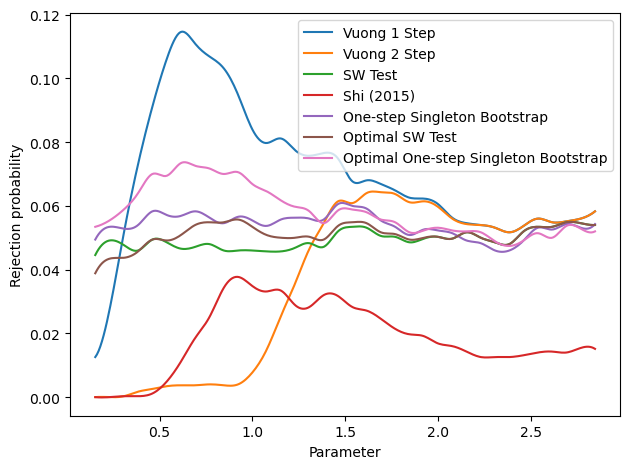

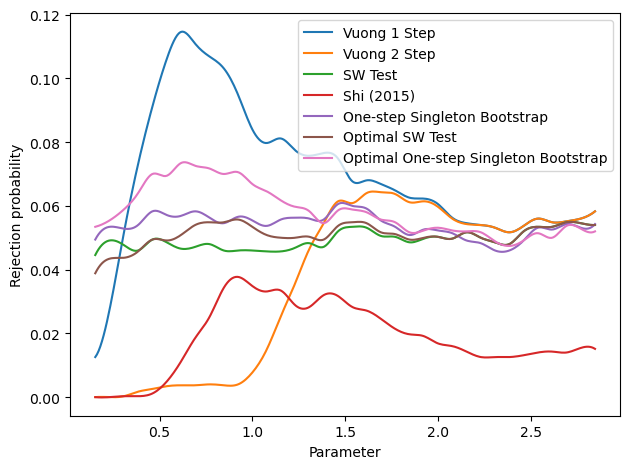

In [7]:
epsilon=.5
nobs = 200
alpha=.05

mc_run_size(nobs,epsilon,data_tuned_epsilon=data_tuned_epsilon,alpha=alpha)

# Power stuff, alpha=.05,n=200

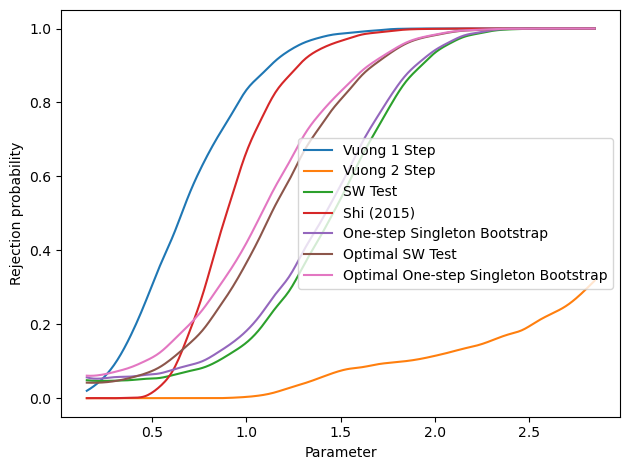

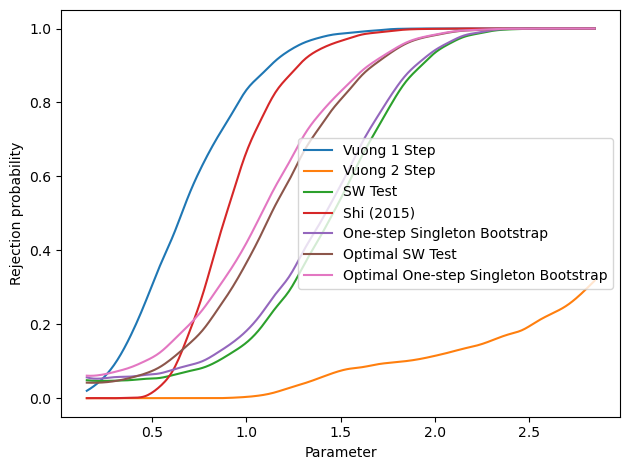

In [8]:
nobs = 200
alpha=.05

mc_run_power(nobs,epsilon,data_tuned_epsilon=data_tuned_epsilon,alpha=alpha)

# extra size sims, alpha=.01,n=100 + n=200, alpha =.01

0.0 [0.98285714 0.01       0.00714286]
0.0 [0.98285714 0.01       0.00714286]
0.07692307692307693 [0.98142857 0.00857143 0.01      ]
0.07692307692307693 [0.98142857 0.00857143 0.01      ]
0.15384615384615385 [0.98285714 0.00571429 0.01142857]
0.15384615384615385 [0.98285714 0.00571429 0.01142857]
0.23076923076923078 [0.99142857 0.00428571 0.00428571]
0.23076923076923078 [0.99142857 0.00428571 0.00428571]
0.3076923076923077 [0.98857143 0.00571429 0.00571429]
0.3076923076923077 [0.98857143 0.00571429 0.00571429]
0.38461538461538464 [0.99       0.00428571 0.00571429]
0.38461538461538464 [0.99       0.00428571 0.00571429]
0.46153846153846156 [0.98142857 0.00714286 0.01142857]
0.46153846153846156 [0.98142857 0.00714286 0.01142857]
0.5384615384615385 [0.98       0.00714286 0.01285714]
0.5384615384615385 [0.98       0.00714286 0.01285714]
0.6153846153846154 [0.98285714 0.00714286 0.01      ]
0.6153846153846154 [0.98285714 0.00714286 0.01      ]
0.6923076923076923 [0.98857143 0.00571429 0.0057

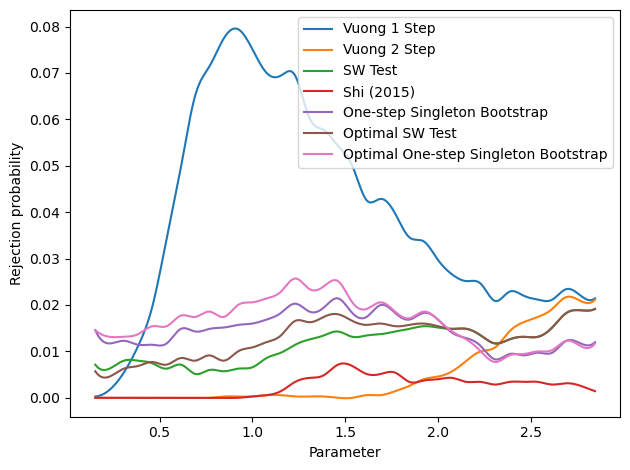

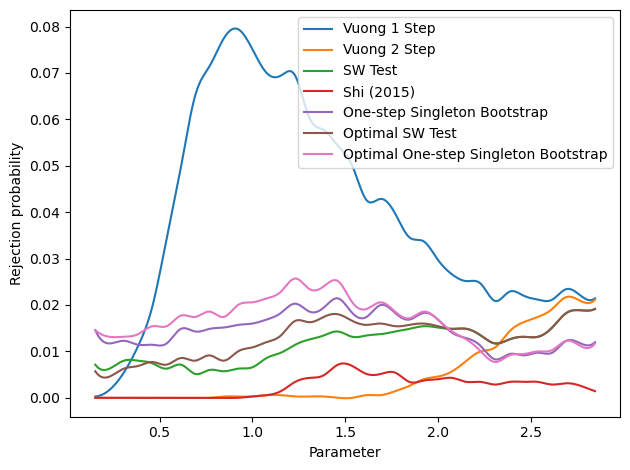

In [9]:
nobs =100
alpha=.01

mc_run_size(nobs,epsilon,data_tuned_epsilon=data_tuned_epsilon,alpha=alpha)

0.0 [0.99       0.00571429 0.00428571]
0.0 [0.99       0.00571429 0.00428571]
0.07692307692307693 [0.98428571 0.00857143 0.00714286]
0.07692307692307693 [0.98428571 0.00857143 0.00714286]
0.15384615384615385 [0.98428571 0.00428571 0.01142857]
0.15384615384615385 [0.98428571 0.00428571 0.01142857]
0.23076923076923078 [0.98       0.00714286 0.01285714]
0.23076923076923078 [0.98       0.00714286 0.01285714]
0.3076923076923077 [0.98428571 0.00571429 0.01      ]
0.3076923076923077 [0.98428571 0.00571429 0.01      ]
0.38461538461538464 [0.98571429 0.00571429 0.00857143]
0.38461538461538464 [0.98571429 0.00571429 0.00857143]
0.46153846153846156 [0.98714286 0.00571429 0.00714286]
0.46153846153846156 [0.98714286 0.00571429 0.00714286]
0.5384615384615385 [0.97285714 0.00857143 0.01857143]
0.5384615384615385 [0.97285714 0.00857143 0.01857143]
0.6153846153846154 [0.96428571 0.01571429 0.02      ]
0.6153846153846154 [0.96428571 0.01571429 0.02      ]
0.6923076923076923 [0.97428571 0.00857143 0.0171

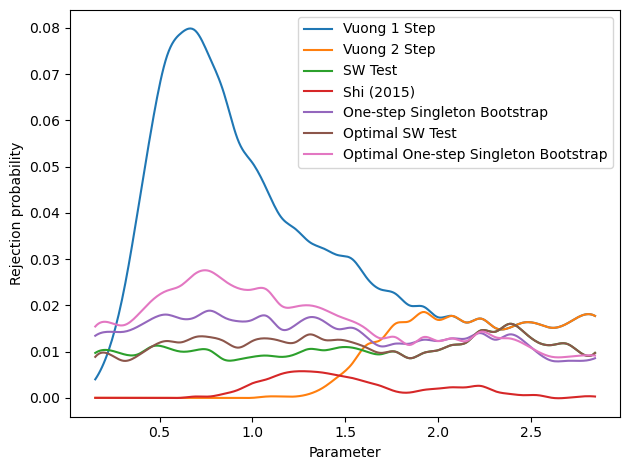

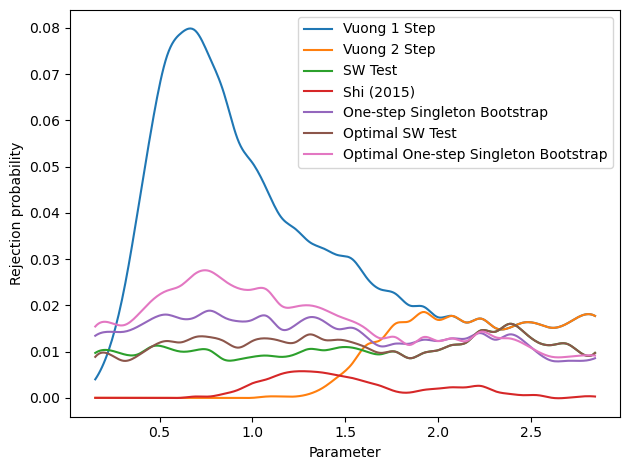

In [10]:
nobs = 200
alpha=.01

mc_run_size(nobs,epsilon,data_tuned_epsilon=data_tuned_epsilon,alpha=alpha)

# Extra Power Sims , alpha=.01,n=100 + n=200, alpha =.01

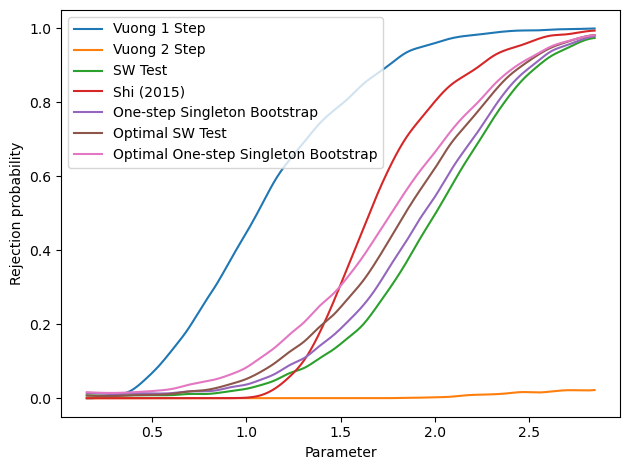

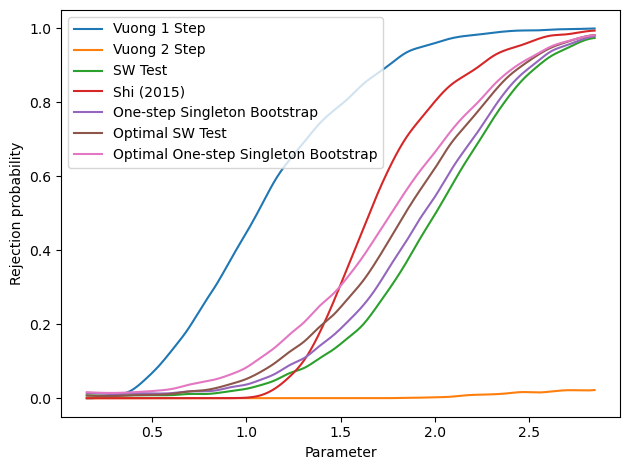

In [11]:
nobs = 100
alpha=.01
mc_run_power(nobs,epsilon,data_tuned_epsilon=data_tuned_epsilon,alpha=alpha)

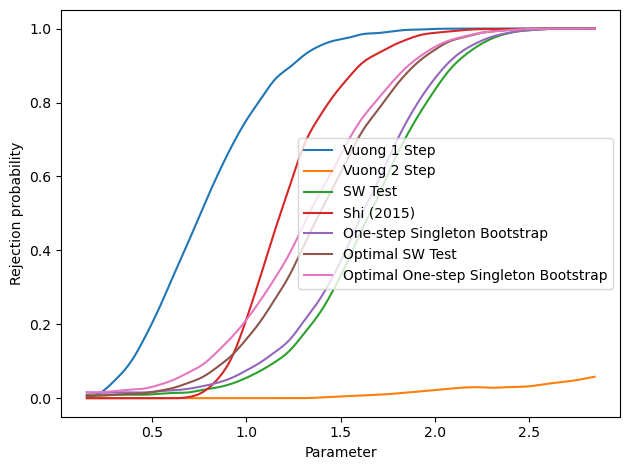

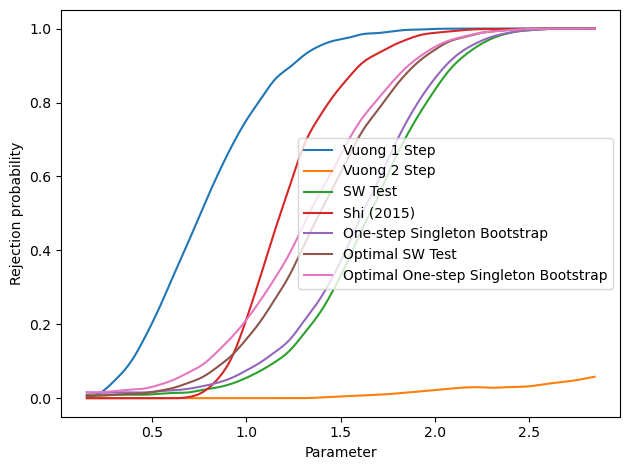

In [12]:
nobs = 200
alpha=.01
mc_run_power(nobs,epsilon,data_tuned_epsilon=data_tuned_epsilon,alpha=alpha)